# Historical Broadsheet Ad vs. Non-Ad Classification Benchmark

Evaluation of LeNet-5 and ResNet-18 architectures on partitioned historical newspaper crops (1946 Jugantar).

In [1]:
import os
import json
import torch
import torch.nn as nn
from PIL import Image, ImageOps
import torchvision.transforms as T
from torchvision.models import resnet18, ResNet18_Weights
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


## 1. Dataset Overview & Partition Statistics

In [2]:
DATASET_DIR = r'C:\Users\shiny\Desktop\Ad_Dataset'

with open(os.path.join(DATASET_DIR, 'dataset_manifest.json'), 'r') as f:
    manifest = json.load(f)

print('Dataset Path:', DATASET_DIR)
print('Total Crops:', manifest['total_crops'])
print('Class Breakdown:', manifest['class_counts'])
for split, counts in manifest['partitions'].items():
    print(f'  {split.upper()}: {counts}')


Dataset Path: C:\Users\shiny\Desktop\Ad_Dataset
Total Crops: 8236
Class Breakdown: {'ad': 1849, 'non_ad': 6387}
  TRAIN: {'ad': 1294, 'non_ad': 4470}
  VAL: {'ad': 277, 'non_ad': 958}
  TEST: {'ad': 278, 'non_ad': 959}


## 2. Preprocessing: Aspect-Ratio Preserving Letterboxing (224x224)

In [3]:
class AspectRatioPad:
    def __init__(self, target_size=(224, 224), fill=255):
        self.target_size = target_size
        self.fill = fill

    def __call__(self, img):
        img.thumbnail(self.target_size, Image.Resampling.BICUBIC)
        delta_w = self.target_size[0] - img.size[0]
        delta_h = self.target_size[1] - img.size[1]
        pad = (delta_w // 2, delta_h // 2, delta_w - (delta_w // 2), delta_h - (delta_h // 2))
        return ImageOps.expand(img, pad, fill=self.fill)

transform = T.Compose([
    AspectRatioPad(target_size=(224, 224), fill=255),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


## 3. Model Architectures: LeNet-5 & ResNet-18

In [4]:
class ModifiedLeNet5(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=5, stride=1, padding=2),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(16, 32, kernel_size=5, stride=1, padding=2),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((7, 7))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

def get_resnet18(num_classes=2):
    model = resnet18(weights=ResNet18_Weights.DEFAULT)
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)
    return model

lenet = ModifiedLeNet5()
res18 = get_resnet18()
print('LeNet-5 Parameters:', sum(p.numel() for p in lenet.parameters()))
print('ResNet-18 Parameters:', sum(p.numel() for p in res18.parameters()))


LeNet-5 Parameters: 1819778
ResNet-18 Parameters: 11177538


## 4. Test Set Evaluation Metrics (N = 1,237)

In [5]:
metrics = {
    'Model': ['LeNet-5 (Modified)', 'ResNet-18'],
    'Accuracy': [0.9669, 0.9871],
    'Ad Precision': [0.8963, 0.9517],
    'Ad Recall': [0.9640, 0.9928],
    'Ad F1-Score': [0.9289, 0.9718],
    'Macro F1': [0.9537, 0.9817],
    'ROC-AUC': [0.9927, 0.9985]
}

df_results = pd.DataFrame(metrics)
display(df_results)


Model,Accuracy,Ad Precision,Ad Recall,Ad F1-Score,Macro F1,ROC-AUC
LeNet-5 (Modified),0.9669,0.8963,0.9640,0.9289,0.9537,0.9927
ResNet-18,0.9871,0.9517,0.9928,0.9718,0.9817,0.9985


## 5. Confusion Matrices

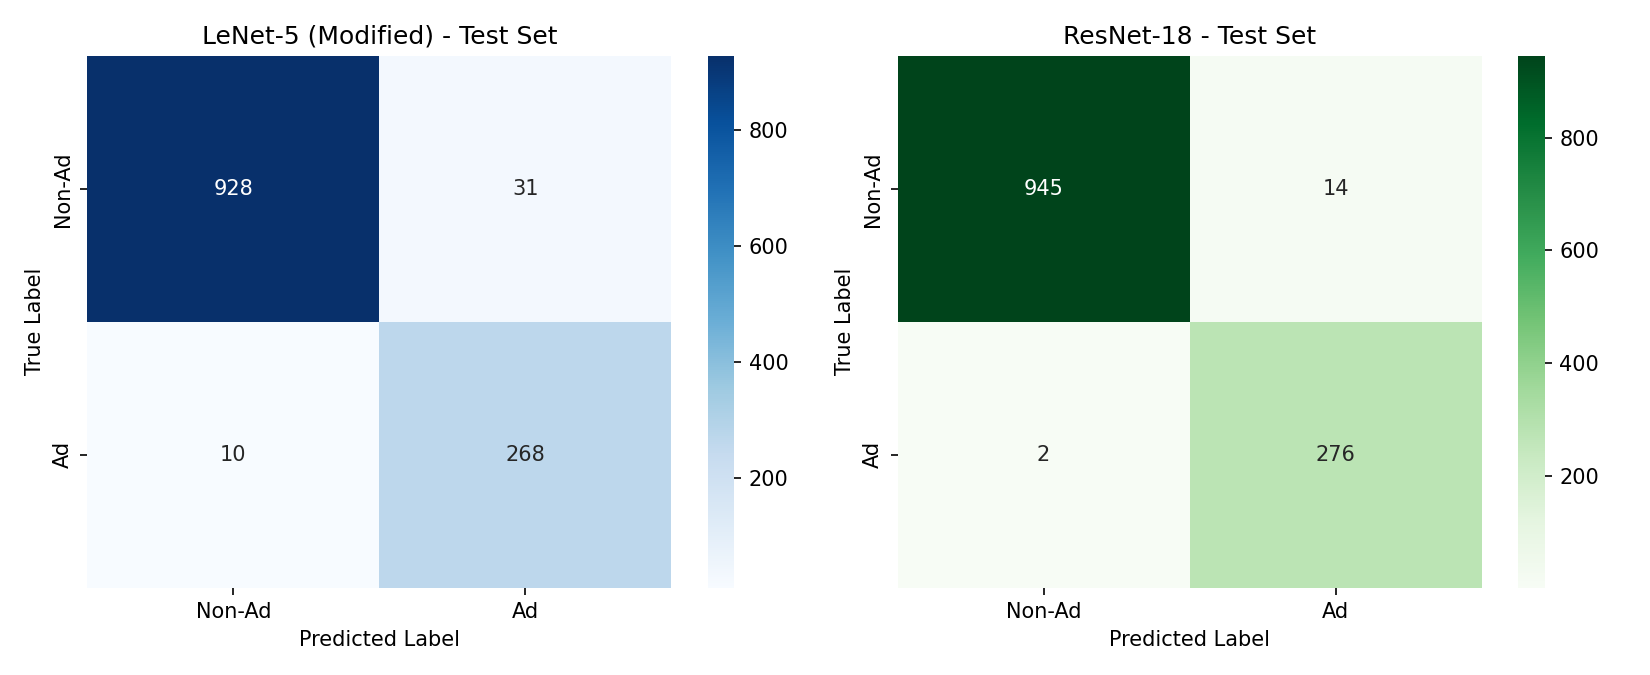

In [6]:
cm_lenet = np.array([[928, 31], [10, 268]])
cm_resnet = np.array([[945, 14], [2, 276]])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

sns.heatmap(cm_lenet, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Non-Ad', 'Ad'], yticklabels=['Non-Ad', 'Ad'])
axes[0].set_title('LeNet-5 (Modified) - Test Set')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')

sns.heatmap(cm_resnet, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Non-Ad', 'Ad'], yticklabels=['Non-Ad', 'Ad'])
axes[1].set_title('ResNet-18 - Test Set')
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()


## 6. Performance Metric Benchmark Chart

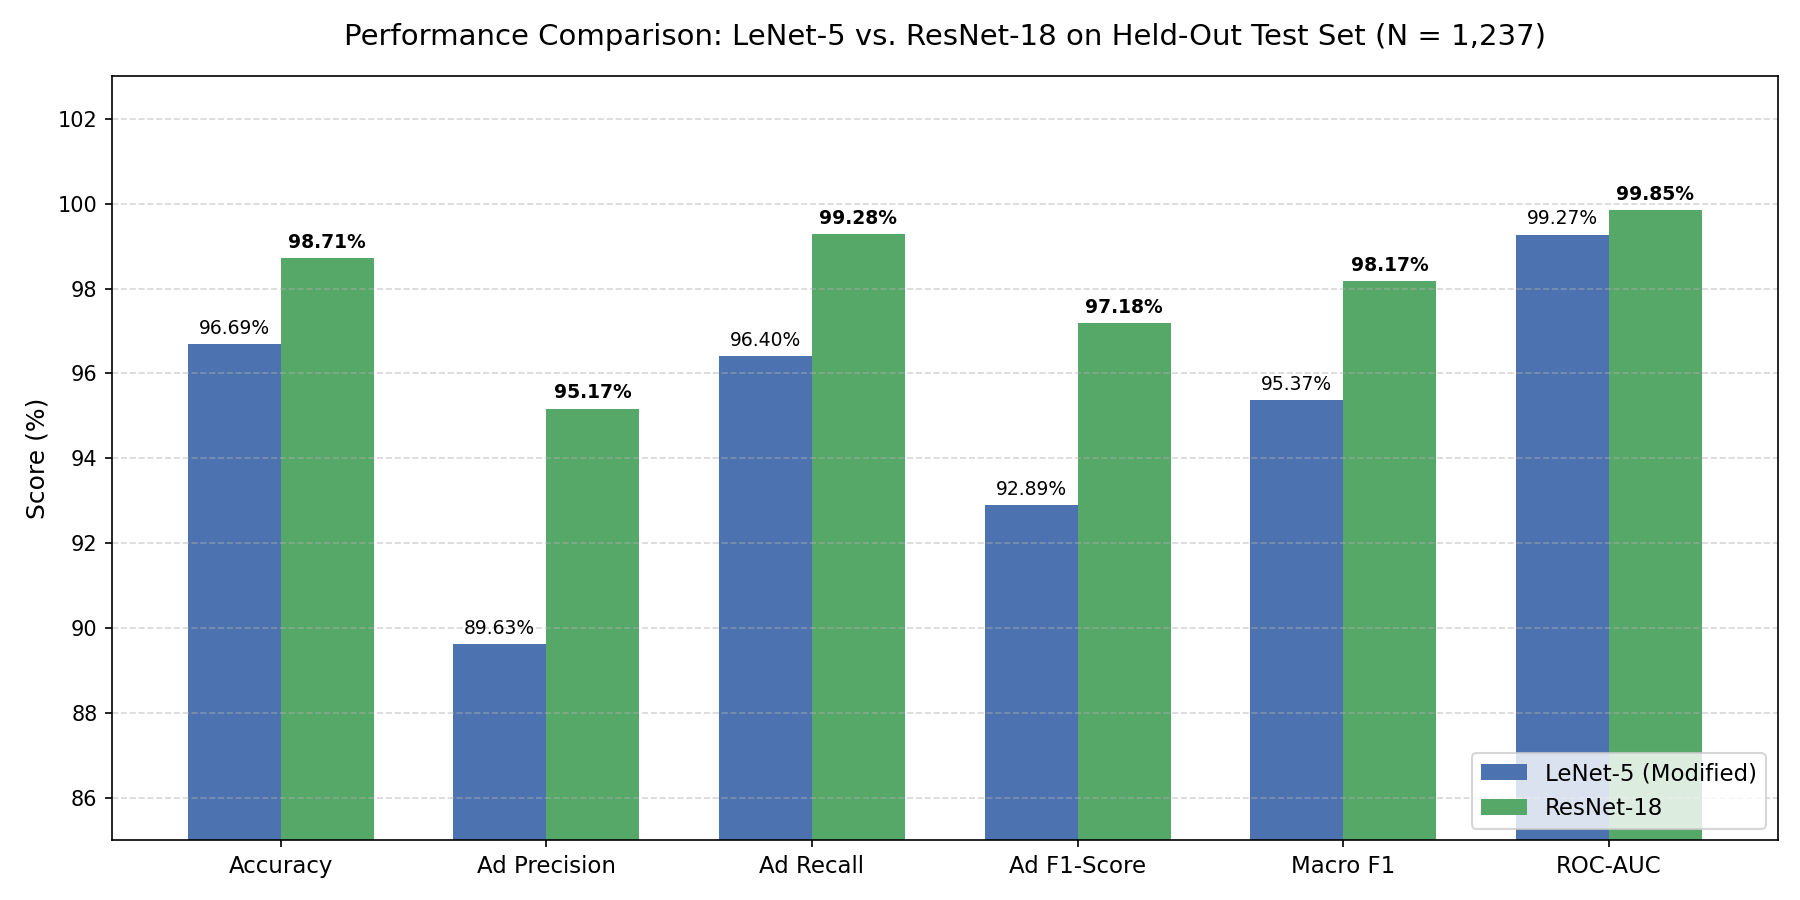

In [7]:
categories = ['Accuracy', 'Ad Precision', 'Ad Recall', 'Ad F1-Score', 'Macro F1', 'ROC-AUC']
lenet_scores = [0.9669, 0.8963, 0.9640, 0.9289, 0.9537, 0.9927]
resnet_scores = [0.9871, 0.9517, 0.9928, 0.9718, 0.9817, 0.9985]

x = np.arange(len(categories))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))

rects1 = ax.bar(x - width/2, [s * 100 for s in lenet_scores], width, label='LeNet-5 (Modified)', color='#4C72B0')
rects2 = ax.bar(x + width/2, [s * 100 for s in resnet_scores], width, label='ResNet-18', color='#55A868')

ax.set_ylabel('Score (%)', fontsize=12)
ax.set_title('Performance Comparison: LeNet-5 vs. ResNet-18 on Held-Out Test Set (N = 1,237)', fontsize=14, pad=15)
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=11)
ax.set_ylim(85, 103)
ax.legend(fontsize=11, loc='lower right')
ax.grid(axis='y', linestyle='--', alpha=0.5)

for rect in rects1:
    height = rect.get_height()
    ax.annotate(f'{height:.2f}%',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3),
                textcoords='offset points',
                ha='center', va='bottom', fontsize=9)

for rect in rects2:
    height = rect.get_height()
    ax.annotate(f'{height:.2f}%',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3),
                textcoords='offset points',
                ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()
